In [40]:
from pathlib import Path
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator
from CITNP.models.causalinferencemodel import CausalInferenceModel, LocalLatentCausalInferenceModel
import torch
from functools import partial
from CITNP.utils.datautils import transformer_inference_split_withpadding
from CITNP.trainer.causalinferencetrainer import send_to_device
import matplotlib.pyplot as plt
import numpy as np

In [55]:
model_path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/experiments/results/uniform_cnp2/model_0.pt"
)

In [56]:
DATA_ARGS = {
    "sample_size": 1000,
    "num_variables": 2,
    "function_generator": "simplegplvm",
    "graph_type": ["ER"],
    "graph_degrees": [1],
    "iterations_per_epoch": 1,
    "batch_size": 1,
}

train_dataset = InterventionDatasetGenerator(**DATA_ARGS)
collator = partial(
    transformer_inference_split_withpadding,
    cntxt_split=[0.75, 0.8],
    sample_size=1000,
    is_training=False,
)
loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=None,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False,
    collate_fn=collator(),
)

# from CITNP.utils.datautils import MultipleFileDataset

# work_dir = Path(
#     "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP"
# )

# data_dir = work_dir / "datasets/synth_training_data" / "anticausal_simplegplvm_['ER']_2_1000" / "val"
# val_files = list(data_dir.iterdir())
# train_dataset = MultipleFileDataset([i for i in val_files if i.suffix == ".hdf5"])

# collator = partial(
#     transformer_inference_split_withpadding,
#     cntxt_split=[0.75, 0.8],
#     sample_size=1000,
#     is_training=False,
# )
# loader = torch.utils.data.DataLoader(
#     train_dataset,
#     batch_size=1,
#     shuffle=True,
#     num_workers=0,
#     pin_memory=True,
#     persistent_workers=False,
#     collate_fn=collator(),
# )

In [43]:
from CITNP.utils.configs import LocalLatentConfig


MODEL_ARGS = {
    "d_model": 256,
    "emb_depth": 2,
    "decoder_depth": 0,
    "dim_feedforward": 1024,
    "nhead": 8,
    "dropout": 0.0,
    "num_layers_encoder": 8,
    "num_z_samples_train": 10,
    "num_z_samples_eval": 10,
    "mean_loss_across_samples": False,
    "num_nodes": 2,
    "device": "cpu",
    "dtype": torch.float32,
}
config = LocalLatentConfig(**MODEL_ARGS)

model = LocalLatentCausalInferenceModel(config=config)
model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

In [59]:
from CITNP.utils.configs import CausalInfModelConfig


MODEL_ARGS = {
    "d_model": 256,
    "emb_depth": 2,
    "dim_feedforward": 1024,
    "nhead": 8,
    "dropout": 0.0,
    "num_layers_encoder": 8,
    "num_nodes": 2,
    "device": "cpu",
    "dtype": torch.float32,
    "mean_loss_across_samples": False,
}
config = CausalInfModelConfig(**MODEL_ARGS)

model = CausalInferenceModel(config=config)
model.load_state_dict(torch.load(model_path))

RuntimeError: Error(s) in loading state_dict for CausalInferenceModel:
	size mismatch for predictor.2.weight: copying a param with shape torch.Size([2, 256]) from checkpoint, the shape in current model is torch.Size([256, 256]).
	size mismatch for predictor.2.bias: copying a param with shape torch.Size([2]) from checkpoint, the shape in current model is torch.Size([256]).

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


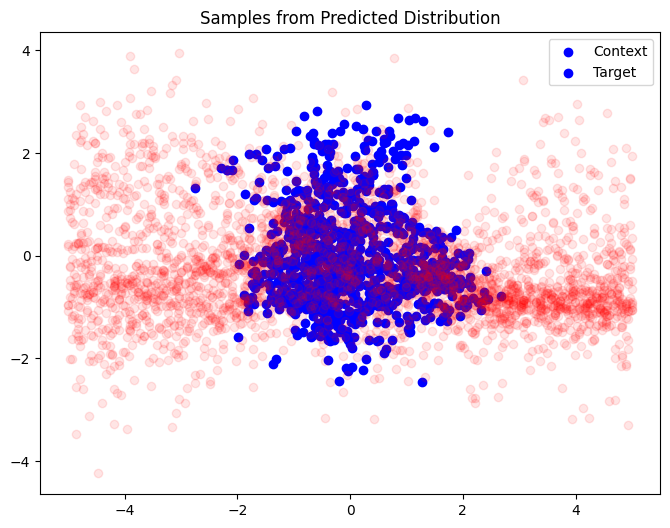

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


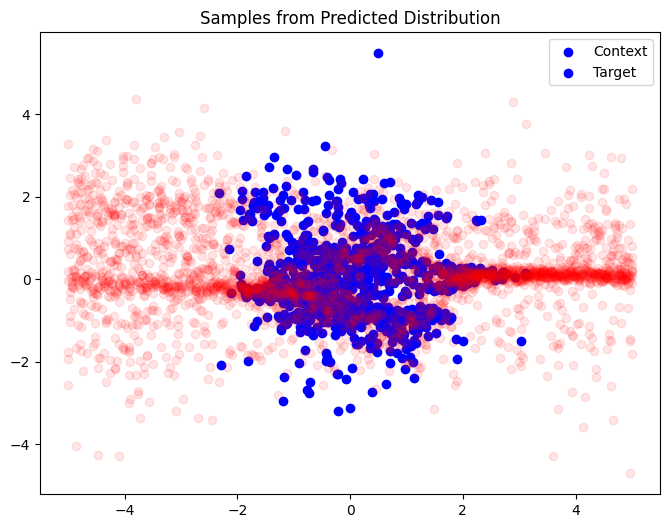

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


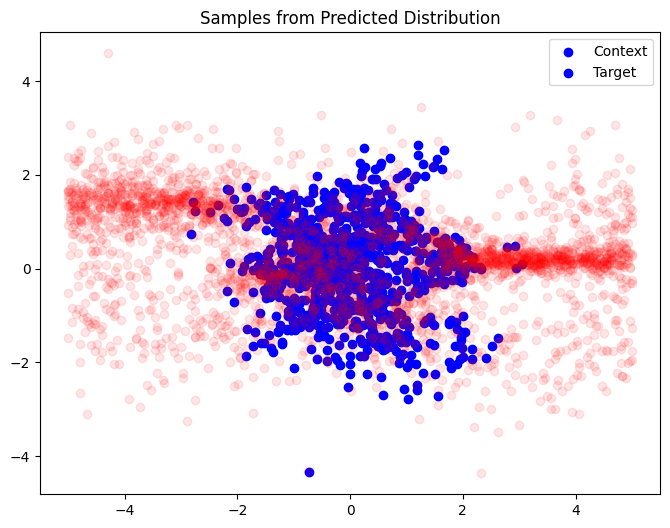

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0
torch.Size([10, 1, 300, 1])


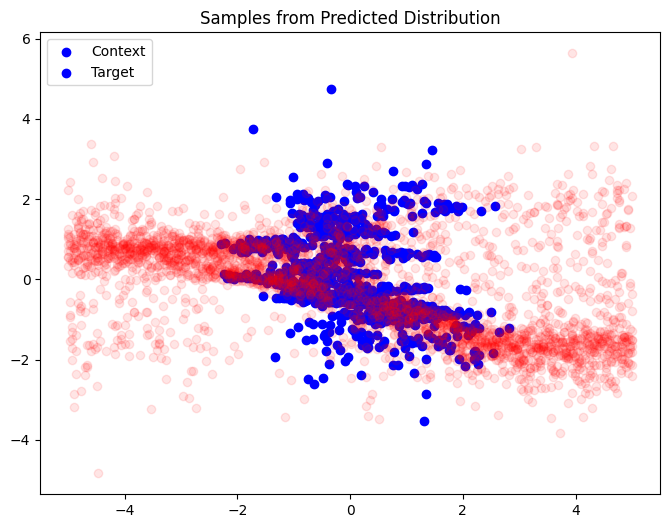

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


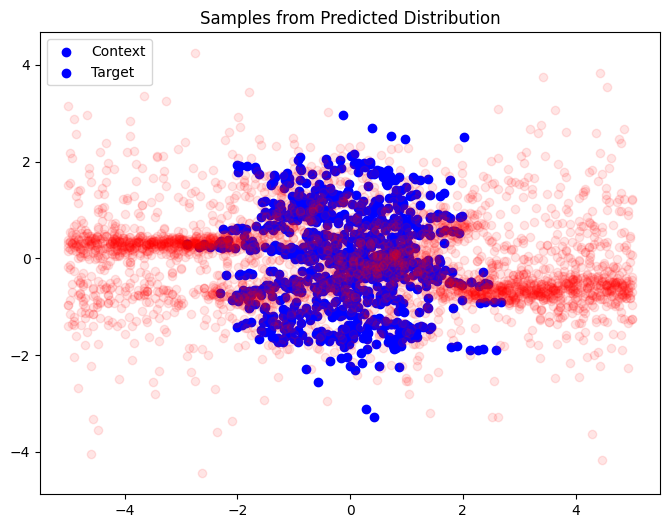

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


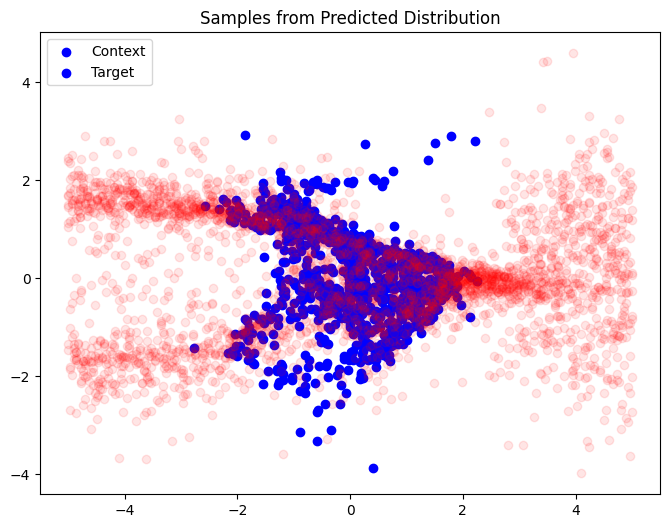

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0
torch.Size([10, 1, 300, 1])


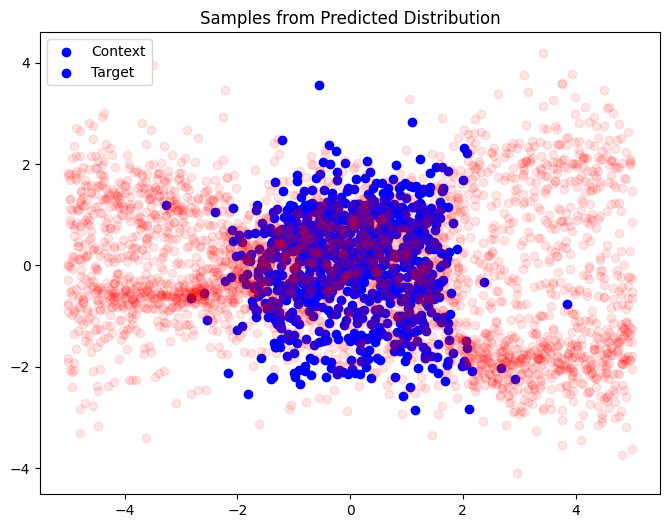

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


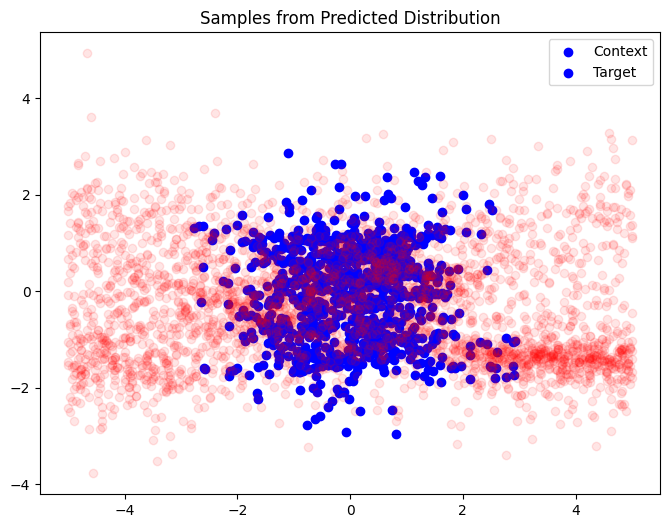

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0
torch.Size([10, 1, 300, 1])


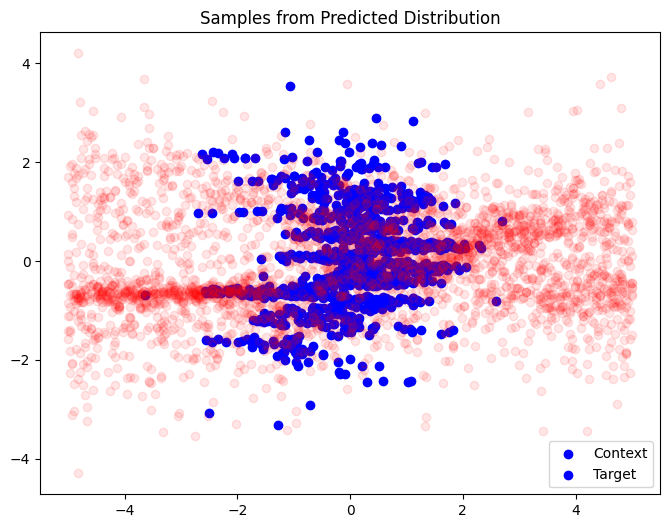

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0
torch.Size([10, 1, 300, 1])


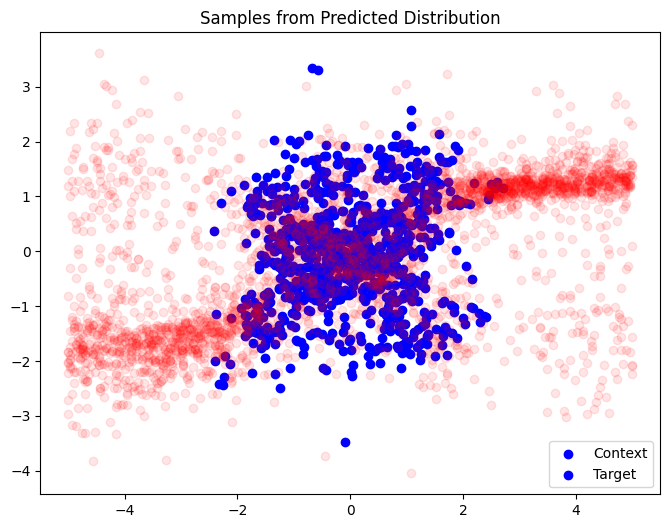

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


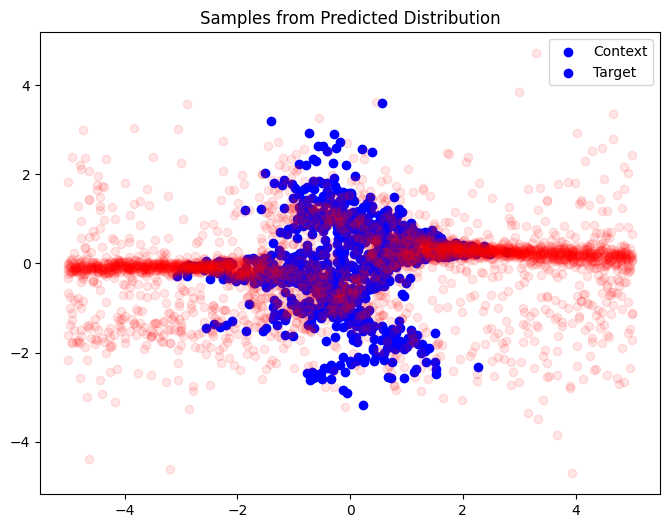

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


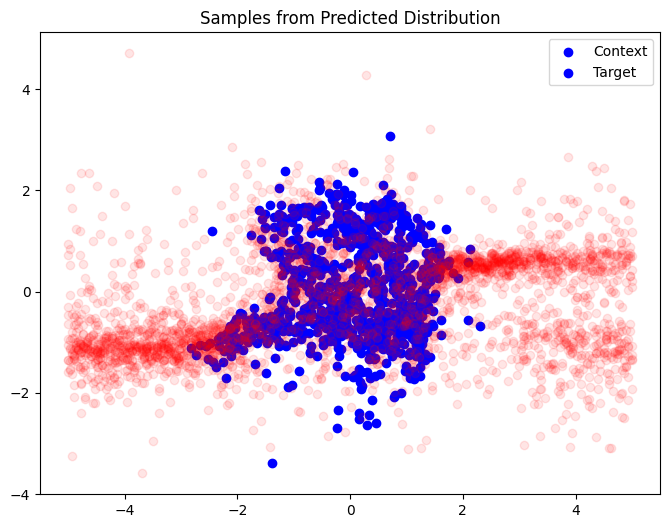

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


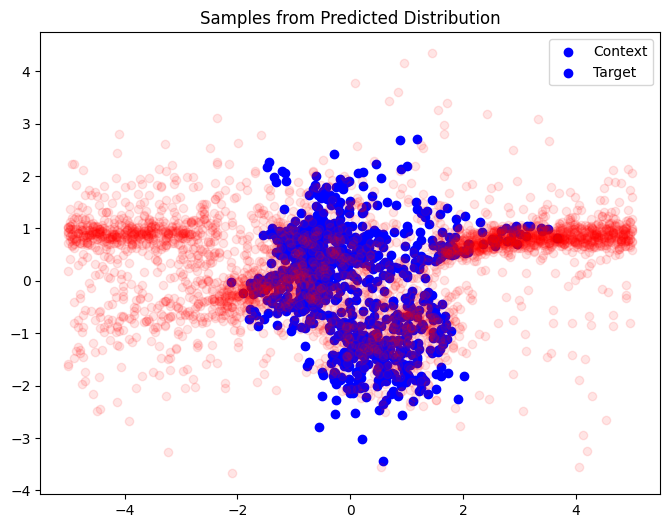

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


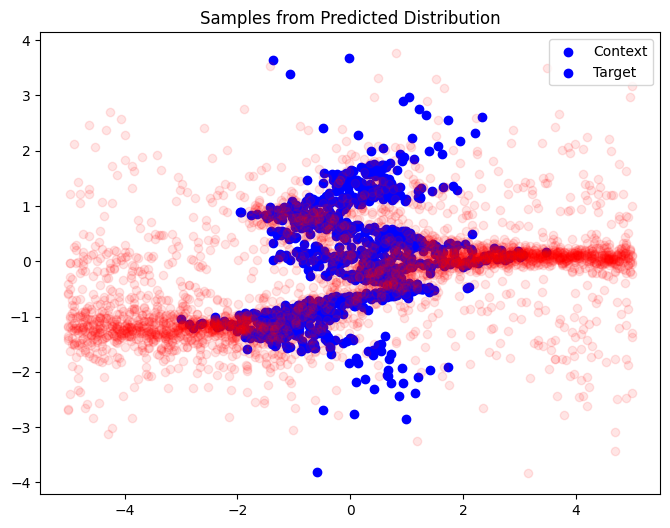

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


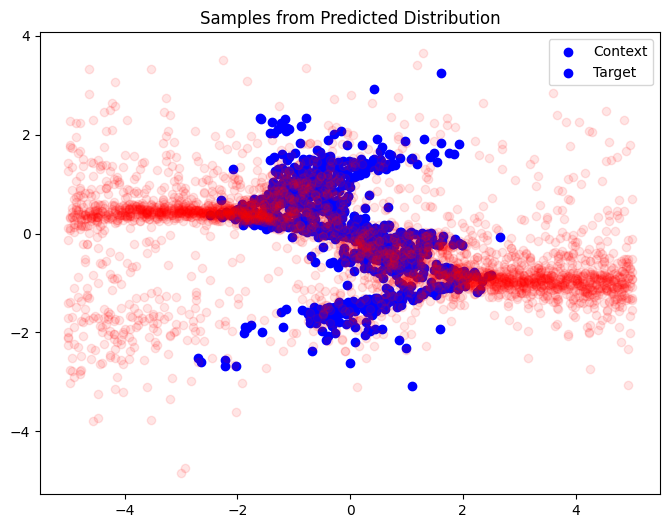

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0
torch.Size([10, 1, 300, 1])


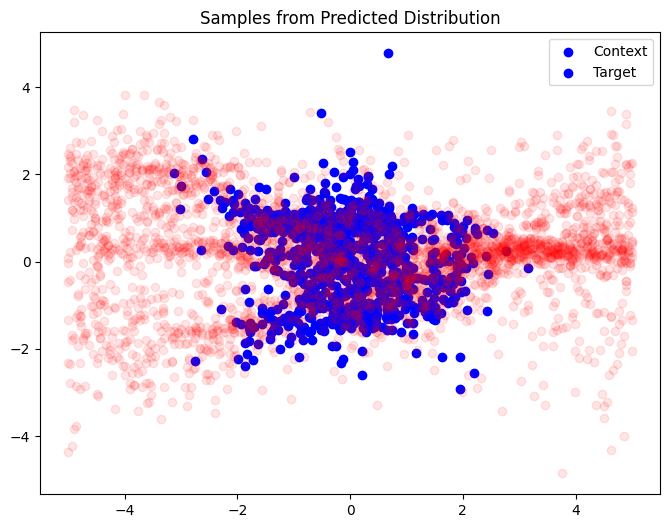

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


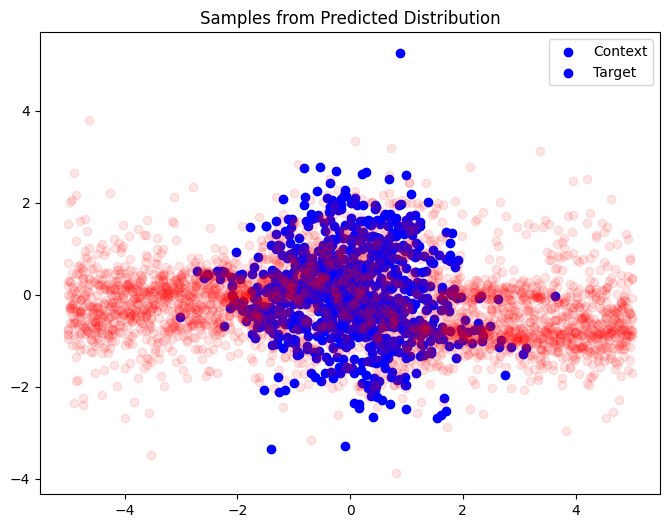

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0
torch.Size([10, 1, 300, 1])


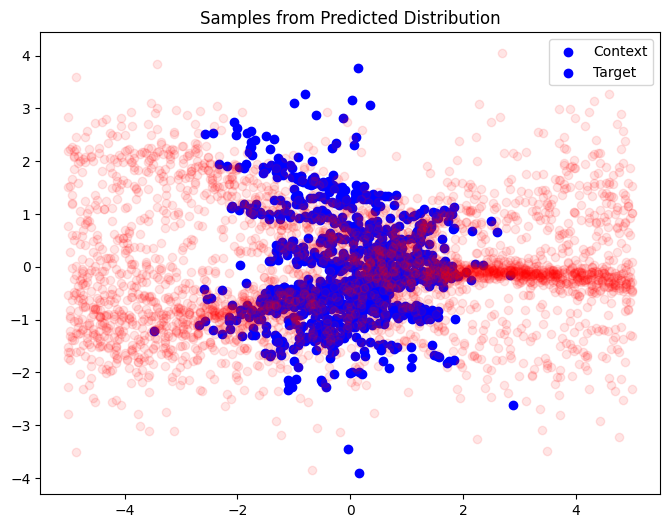

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1
torch.Size([10, 1, 300, 1])


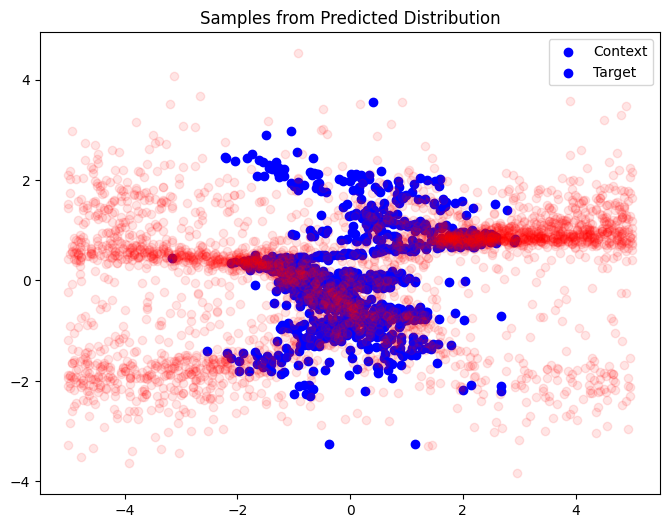

In [54]:
from CITNP.utils.plotting import plot_context_target_predictions
import matplotlib.pyplot as plt
import IPython.display as display
from CITNP.utils.utils import gather_by_node


DEVICE = "cuda"

model.eval()
model.to(DEVICE)

TOTAL_PLOTS = 20
done = False

total_plots = 0
for iteration in range(20):
    for batch in loader:
        total_plots += 1
        if total_plots >= TOTAL_PLOTS:
            done = True
            break
        context, target, intvn_indices, outcome_indices, masks, graph = (
            send_to_device(
                list(batch),
                device=DEVICE,
            )
        )
        new_target = (
            torch.linspace(-5, 5, 300).unsqueeze(1).repeat(1, 2)[None, :, :, None]
        )
        new_target = new_target.to(DEVICE)
        mean, std, _, _, _, _ = model(
            context_data=context,
            target_data=new_target,
            intervention_index=intvn_indices,
            outcome_index=outcome_indices,
            variable_mask=None,
        )
        print(graph[0])
        print(f"Intervention: {intvn_indices[0]}")
        print(f"Outcome: {outcome_indices[0]}")
        print(mean.shape)
        if mean.ndim == 3:
            mean = mean.unsqueeze(0)
            std = std.unsqueeze(0)
        # fig = plot_context_target_predictions(
        #     context=context,
        #     target=target,
        #     new_target=new_target,
        #     pred_mean=mean,
        #     pred_std=std,
        #     treatment_idx=intvn_indices,
        #     outcome_index=outcome_indices,
        #     return_fig=True
        # )
        # fig.show()
        # Sample from the predicted distribution
        dist = torch.distributions.Normal(mean, std)
        samples = dist.sample((1,))[0]  # Shape: (num_samples, batch, time, features)

        # Optionally overlay the true context and target points
        context_intvn = gather_by_node(
            context, intvn_indices,
        )
        context_outcome = gather_by_node(
            context, outcome_indices,
        )
        fig, ax = plt.subplots(figsize=(8, 6))

        ax.scatter(
            context_intvn.cpu().numpy(),
            context_outcome.cpu().numpy(),
            label="Context",
            c="blue"
        )
        target_intvn = gather_by_node(
            target, intvn_indices,
        )
        target_outcome = gather_by_node(
            target, outcome_indices,
        )
        ax.scatter(
            target_intvn.cpu().numpy(),
            target_outcome.cpu().numpy(),
            label="Target",
            c="blue"
        )

        # Plot samples instead of mean/std
        for i in range(samples.shape[0]):
            ax.scatter(
                new_target[0, :, 0, 0].cpu().numpy(),
                samples[i, 0, :, 0].cpu().numpy(),
                alpha=0.1,
                c="red",
            )



        ax.set_title("Samples from Predicted Distribution")
        ax.legend()
        plt.show()
    if done:
        break


In [ ]:
new_target[0, :, 0, 0].cpu().numpy().shape

In [ ]:
samples[i, 0, :, 0].cpu().numpy().shape

In [ ]:
samples.shape

In [ ]:
new_target = torch.linspace(-3, 3, 500).unsqueeze(1).repeat(1, 2)

In [ ]:
new_target.shape

In [ ]:
target.shape